
# Data Preparation of the Heart Diagnoses file

In [18]:
import pandas as pd
import numpy as np
import seaborn as sns
import sys
import os
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '../..')))
from src.utils import data_understanding as du





heart_diagnoses_df = pd.read_csv("../../data/raw/heart_diagnoses_1.csv")



## Data Cleaning

In [19]:
#drop columns with information not relevant for the analysis: free text columns, reports columns,unusefull columns
heart_diagnoses_df = heart_diagnoses_df.drop(columns=["CT", "MRI", "X-ray", "Ultrasound", "ECG", "CATH", "invasions", "reports","chief_complaint", "physical_exam","HPI","anchor_year","note_seq","note_type"])
heart_diagnoses_df_columns= du.get_cols(heart_diagnoses_df)
print("Columns in heart diagnoses dataset:",heart_diagnoses_df_columns) 

Columns in heart diagnoses dataset: ['note_id', 'subject_id', 'hadm_id', 'charttime', 'storetime', 'subject_id_dx', 'icd_code', 'long_title', 'gender', 'age', 'dod']


In [20]:
#Missing value analysis
#age and gender have missing values but they can be usfull for the analysis so we will keep them
#dod has many missing values can be  that the patient witout dod is alive or the data is missing, so is ambiguous, we will drop it
heart_diagnoses_df=heart_diagnoses_df.drop(columns=["dod"])


In [21]:
# Calcola il numero di occorrenze per ogni icd_code
icd_counts = heart_diagnoses_df['icd_code'].value_counts()

# Calcola Q1, Q3 e IQR
q1 = icd_counts.quantile(0.25)
q3 = icd_counts.quantile(0.75)
iqr = q3 - q1

# Calcola i limiti
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

print(f"Q1 (25%): {q1}")
print(f"Q3 (75%): {q3}")
print(f"IQR: {iqr}")
print(f"Lower limit: {lower_limit}")
print(f"Upper limit: {upper_limit}")

# Identifica gli icd_code da rimuovere (sotto il limite inferiore)
rare_icd_codes_iqr = icd_counts[icd_counts < lower_limit].index

print(f"\nICD codes da rimuovere (sotto il limite): {len(rare_icd_codes_iqr)}")
print(rare_icd_codes_iqr.tolist())

# Rimuovi gli icd_code rari
heart_diagnoses_df = heart_diagnoses_df[~heart_diagnoses_df['icd_code'].isin(rare_icd_codes_iqr)]

print(f"\nShape dopo rimozione: {heart_diagnoses_df.shape}")
print(f"ICD codes rimasti: {heart_diagnoses_df['icd_code'].nunique()}")
icd_counts_after = heart_diagnoses_df['icd_code'].value_counts()
icd_counts_after

Q1 (25%): 15.0
Q3 (75%): 172.5
IQR: 157.5
Lower limit: -221.25
Upper limit: 408.75

ICD codes da rimuovere (sotto il limite): 0
[]

Shape dopo rimozione: (4864, 10)
ICD codes rimasti: 20


icd_code
I50    1447
I21    1434
I25     645
I48     438
I35     231
I31     153
I47     130
I30      83
I44      70
I34      50
I33      38
I20      36
I49      35
I42      33
I40      16
I24      12
I22       5
I45       5
I46       2
I36       1
Name: count, dtype: int64

In [22]:
#drop icd_code with few occurrences and without any age information
icd_codes_to_drop = icd_counts_after[(icd_counts_after < 30) & (heart_diagnoses_df.groupby('icd_code')['age'].apply(lambda x: x.isna().all()))].index    
heart_diagnoses_df = heart_diagnoses_df[~heart_diagnoses_df['icd_code'].isin(icd_codes_to_drop)]    
print(f"\nShape dopo rimozione icd_code con poche occorrenze e senza età: {heart_diagnoses_df.shape}")
print(f"ICD codes rimasti: {heart_diagnoses_df['icd_code'].nunique()}")
icd_counts_after = heart_diagnoses_df['icd_code'].value_counts()        
icd_counts_after      


Shape dopo rimozione icd_code con poche occorrenze e senza età: (4857, 10)
ICD codes rimasti: 18


icd_code
I50    1447
I21    1434
I25     645
I48     438
I35     231
I31     153
I47     130
I30      83
I44      70
I34      50
I33      38
I20      36
I49      35
I42      33
I40      16
I24      12
I22       5
I36       1
Name: count, dtype: int64

In [23]:
# Calculate median age per icd_code
icd_stats = heart_diagnoses_df.groupby('icd_code')['age'].median().reset_index()

icd_stats.columns = ['icd_code', 'median_age']

# Join median age back to the original dataframe
heart_diagnoses_df = heart_diagnoses_df.merge(icd_stats, on='icd_code', how='left')



# Fill missing age values with the median_age for that icd_code
heart_diagnoses_df['age'] = heart_diagnoses_df['age'].fillna(heart_diagnoses_df['median_age'])
heart_diagnoses_df['age'] = heart_diagnoses_df['age'].astype(int)

# Drop the temporary median_age column
heart_diagnoses_df = heart_diagnoses_df.drop(columns=['median_age'])
heart_diagnoses_df

,note_id,subject_id,hadm_id,charttime,storetime,subject_id_dx,icd_code,long_title,gender,age
0,10000980-DS-20,10000980,29654838,2188-01-06 03:00:00,2188-01-07 23:49:00,10000980,I50,Heart failure,F,75
1,10000980-DS-21,10000980,26913865,2189-07-04 03:00:00,2189-07-04 22:50:00,10000980,I21,Acute myocardial infarction,F,75
2,10002013-DS-8,10002013,24760295,2160-07-13 03:00:00,2160-07-15 16:59:00,10002013,I21,Acute myocardial infarction,NaN,69
3,10002155-DS-8,10002155,23822395,2129-08-19 03:00:00,2129-08-20 15:29:00,10002155,I21,Acute myocardial infarction,NaN,69
4,10004457-DS-10,10004457,28723315,2141-08-14 03:00:00,2141-08-14 21:50:00,10004457,I35,Nonrheumatic aortic valve disorders,M,66
...,...,...,...,...,...,...,...,...,...,...
4852,13690559-DS-19,19998596,24860241,2180-01-24 03:00:00,2180-01-24 20:12:00,13690559,I48,Atrial fibrillation and flutter,NaN,71
4853,14997789-DS-12,19998597,23720781,2131-10-11 03:00:00,2131-10-11 16:17:00,14997789,I31,Other diseases of pericardium,NaN,57
4854,10754991-DS-13,19998598,26940500,2135-04-03 03:00:00,2135-04-05 00:12:00,10754991,I47,Paroxysmal tachycardia,NaN,69
4855,17922874-DS-8,19998599,20343031,2158-05-23 03:00:00,2158-05-23 20:55:00,17922874,I30,Acute pericarditis,NaN,59


In [24]:
#sosbitute missing value of the age calculating the proportion of F and M for each icd_code
np.random.seed(42)  # Per riproducibilità

def fill_with_proportions(group):
    missing_mask = group['gender'].isna()
    if missing_mask.sum() == 0:
        return group
    
    # Ottieni le proporzioni
    value_counts = group['gender'].value_counts()
    proportions = value_counts / value_counts.sum()
    
    # Riempi con valori casuali rispetto alle proporzioni
    group.loc[missing_mask, 'gender'] = np.random.choice(
        value_counts.index, 
        size=missing_mask.sum(), 
        p=proportions.values
    )
    return group

heart_diagnoses_df = heart_diagnoses_df.groupby('icd_code', group_keys=False).apply(fill_with_proportions)

print(f"Missing values in gender: {heart_diagnoses_df['gender'].isna().sum()}")
print("\nGender distribution:")
print(heart_diagnoses_df['gender'].value_counts())



Missing values in gender: 0

Gender distribution:
gender
M    2759
F    2098
Name: count, dtype: int64


/var/folders/d3/b_pspz_d64lf1hwbztqr9l1r0000gn/T/ipykernel_64637/3979612173.py:21: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  heart_diagnoses_df = heart_diagnoses_df.groupby('icd_code', group_keys=False).apply(fill_with_proportions)


In [25]:
icd_gender_counts = heart_diagnoses_df.groupby(['icd_code', 'gender']).size().unstack(fill_value=0)
icd_gender_counts['Total'] = heart_diagnoses_df.groupby('icd_code').size()

# Rinomina le colonne
icd_gender_counts.columns = ['Female', 'Male', 'Total']

# Ordina per Total (decrescente)
icd_gender_counts = icd_gender_counts.sort_values('Total', ascending=False)

print("=== Gender Distribution per ICD Code ===\n")
print(icd_gender_counts)

=== Gender Distribution per ICD Code ===

          Female  Male  Total
icd_code                     
I50          725   722   1447
I21          504   930   1434
I25          239   406    645
I48          215   223    438
I35           85   146    231
I31           86    67    153
I47           49    81    130
I30           50    33     83
I44           43    27     70
I34           36    14     50
I33           11    27     38
I20           16    20     36
I49           16    19     35
I42           12    21     33
I40            1    15     16
I24            4     8     12
I22            5     0      5
I36            1     0      1


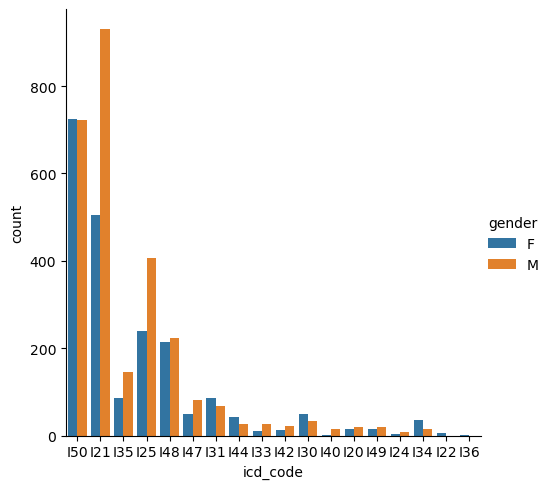

In [26]:
#to visualize the number of female and men for each icd_code
sns.catplot(data=heart_diagnoses_df, x="icd_code", hue="gender",kind="count")

In [27]:
#drop columns that have info achieved in another coloumns 
heart_diagnoses_df=heart_diagnoses_df.drop(columns=["note_id","subject_id_dx"])


In [28]:

#cleaning charttime column : drop the rows where there is an error between charttime and storetime
heart_diagnoses_df = heart_diagnoses_df[heart_diagnoses_df["charttime"] <= heart_diagnoses_df["storetime"]]
#for time analysis i choose to keep only the charttime column and drop the others
heart_diagnoses_df=heart_diagnoses_df.drop(columns=["storetime"])


In [29]:
#final dataset analysis
print("Shape of heart diagnoses dataset:",)
heart_diagnoses_df.shape
print("Info of heart diagnoses dataset:")
heart_diagnoses_df.info()
heart_diagnoses_df_none=du.get_cols_with_none(heart_diagnoses_df)
print("Missing values in each column of heart diagnoses dataset:\n",heart_diagnoses_df_none)
print("Basic statistics of heart diagnoses dataset:")
du.get_basic_stats(heart_diagnoses_df)


Shape of heart diagnoses dataset:
Info of heart diagnoses dataset:
<class 'pandas.core.frame.DataFrame'>
Index: 4848 entries, 0 to 4856
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   subject_id  4848 non-null   int64 
 1   hadm_id     4848 non-null   int64 
 2   charttime   4848 non-null   object
 3   icd_code    4848 non-null   object
 4   long_title  4848 non-null   object
 5   gender      4848 non-null   object
 6   age         4848 non-null   int64 
dtypes: int64(3), object(4)
memory usage: 303.0+ KB
Missing values in each column of heart diagnoses dataset:
 subject_id    False
hadm_id       False
charttime     False
icd_code      False
long_title    False
gender        False
age           False
dtype: bool
Basic statistics of heart diagnoses dataset:


,age
count,4848.000000
mean,70.270421
std,9.404581
min,18.000000
25%,66.000000
50%,69.000000
75%,75.000000
max,95.000000


In [30]:
# mean and median age for each icd_code
icd_stats = heart_diagnoses_df.groupby('icd_code')['age'].agg(['mean', 'median']).reset_index()
icd_stats.columns = ['icd_code', 'mean_age', 'median_age']
print("Mean and median age for each ICD code:\n", icd_stats)

Mean and median age for each ICD code:
    icd_code   mean_age  median_age
0       I20  56.944444        60.0
1       I21  68.883298        69.0
2       I22  90.000000        90.0
3       I24  69.333333        69.0
4       I25  65.962617        66.0
5       I30  59.277108        59.0
6       I31  57.320261        57.0
7       I33  57.078947        59.0
8       I34  71.240000        71.0
9       I35  82.376623        83.0
10      I36  60.000000        60.0
11      I40  49.562500        52.0
12      I42  49.333333        48.0
13      I44  82.753623        84.0
14      I47  68.800000        69.0
15      I48  71.045662        71.0
16      I49  63.285714        64.0
17      I50  74.395156        75.0


<Axes: xlabel='icd_code', ylabel='Count'>

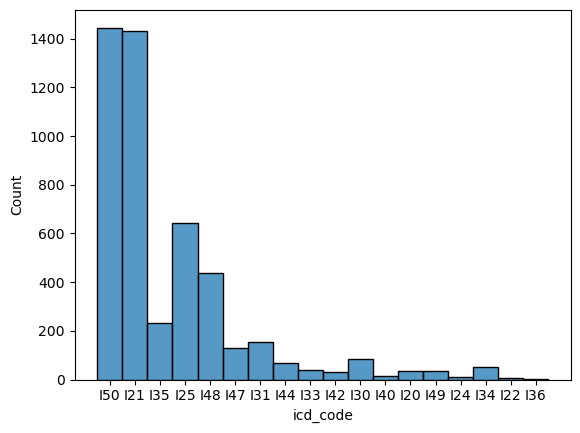

In [31]:
# visualize the new icd_code distribution
sns.histplot(heart_diagnoses_df, x="icd_code")


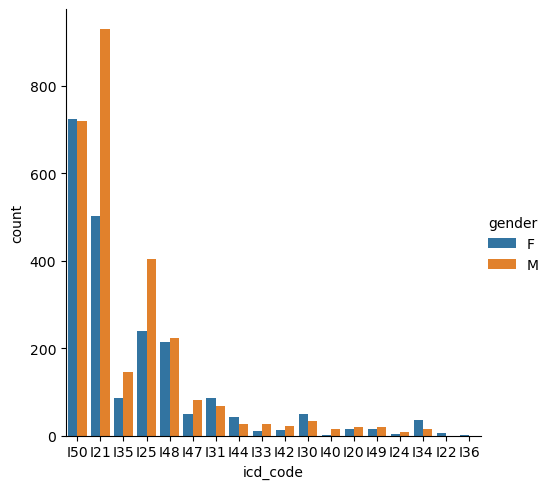

In [32]:
# visualize the number of female and men for each icd_code
sns.catplot(data=heart_diagnoses_df, x="icd_code", hue="gender",kind="count")

<Axes: xlabel='icd_code', ylabel='age'>

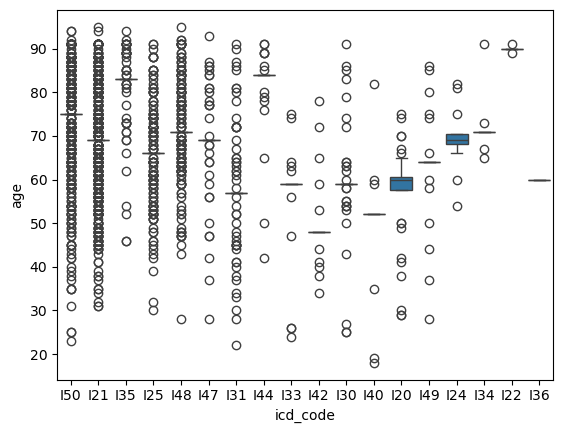

In [33]:
# visualize for each icd_code the age of the patient 
sns.boxplot(data=heart_diagnoses_df,x="icd_code",y="age")

In [34]:
heart_diagnoses_df.to_csv("../../data/processed/hd.csv", index=False)